<a href="https://colab.research.google.com/github/sourish-bhattacharyya/fds-lab/blob/main/Sourish_Bhattacharyya_EXP_4_FDS_16014225009.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files

uploaded = files.upload()

Saving kolkata_unified_dataset.csv to kolkata_unified_dataset.csv


In [2]:
import math
import pandas as pd
import matplotlib.pyplot as plt

In [9]:

fname = next(iter(uploaded))
df = pd.read_csv(fname)
df.head()

,Timestamp,Farm_ID,Volumetric_Moisture_Pct,Sensor_Board_Temperature_C,Raw_Capacitive_ADC,Sensor_Voltage_V,Atm_Pressure_inHg,Atm_Temperature_C,Soil_Temperature_C,SM_Level_15cm,...,SM_Volume_Pct,Hour,Day,Month,DayOfWeek,DayOfYear,Hour_sin,Hour_cos,Day_sin,Day_cos
0,2025-01-05 00:00:00,Kolkata_Farm_1,14.15,17.026336,704,2.271,30.0206,16.38,19.21,1.80,...,21.21,0,5,1,6,5,0.000000,1.000000,0.085965,0.996298
1,2025-01-05 00:15:00,Kolkata_Farm_1,14.14,17.717099,692,2.232,30.0171,17.05,19.36,2.07,...,21.16,0,5,1,6,5,0.000000,1.000000,0.085965,0.996298
2,2025-01-05 00:30:00,Kolkata_Farm_1,14.14,13.012097,700,2.258,30.0167,16.88,19.55,1.91,...,21.06,0,5,1,6,5,0.000000,1.000000,0.085965,0.996298
3,2025-01-05 00:45:00,Kolkata_Farm_1,14.14,14.360777,697,2.248,30.0192,16.39,19.52,2.02,...,20.82,0,5,1,6,5,0.000000,1.000000,0.085965,0.996298
4,2025-01-05 01:00:00,Kolkata_Farm_1,14.14,15.489267,675,2.177,30.0195,16.72,19.73,2.67,...,20.25,1,5,1,6,5,0.258819,0.965926,0.085965,0.996298


In [10]:

pairs = [
    ("Raw_Capacitive_ADC", "Sensor_Voltage_V"),
    ("Hour", "Hour_cos"),
    ("Sensor_Board_Temperature_C", "Atm_Pressure_inHg")
]

labels = [
    "ADC vs Sensor Voltage",
    "Hour vs Hour Cosine",
    "Board Temperature vs Pressure"
]

ADC vs Sensor Voltage: 1.0


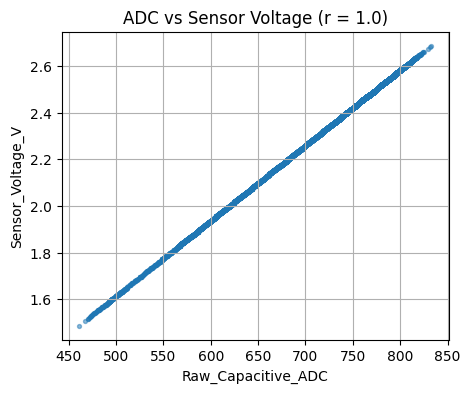

Hour vs Hour Cosine: -0.102


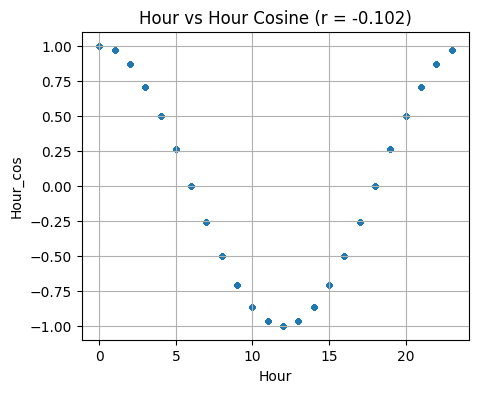

Board Temperature vs Pressure: -0.477


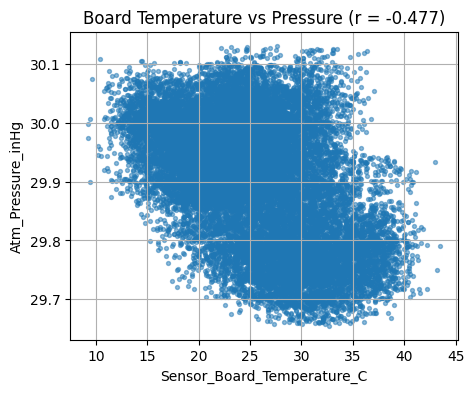

In [11]:
for (x_col, y_col), label in zip(pairs, labels):

    data = df[[x_col, y_col]].dropna()

    r = data[x_col].corr(data[y_col])
    print(label + ":", round(r, 3))

    plt.figure(figsize=(5, 4))
    plt.scatter(data[x_col], data[y_col], s=8, alpha=0.5)
    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.title(label + " (r = " + str(round(r, 3)) + ")")
    plt.grid(True)
    plt.show()

In [12]:
def correlation(x, y):
    n = len(x)
    mean_x = sum(x) / n
    mean_y = sum(y) / n

    num = 0
    sum_sq_x = 0
    sum_sq_y = 0

    for i in range(n):
        dx = x[i] - mean_x
        dy = y[i] - mean_y
        num += dx * dy
        sum_sq_x += dx ** 2
        sum_sq_y += dy ** 2



    return num / math.sqrt(sum_sq_x * sum_sq_y)

In [15]:
clean = df.dropna(subset=[col for pair in pairs for col in pair])

for (x_col, y_col), label in zip(pairs, labels):
    x = clean[x_col].tolist()
    y = clean[y_col].tolist()
    r = correlation(x, y)
    print(label + ":", round(r, 3))


ADC vs Sensor Voltage: 1.0
Hour vs Hour Cosine: -0.102
Board Temperature vs Pressure: -0.477


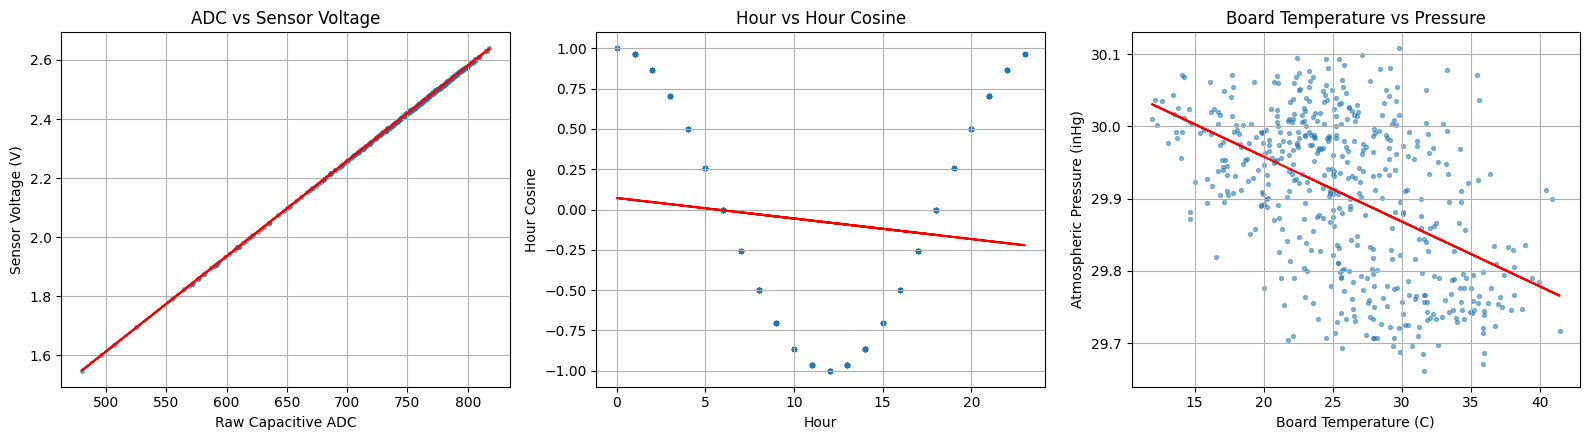

In [14]:
# using a sample of 500 rows so the plots don't get too crowded
s = clean.sample(min(500, len(clean)), random_state=1)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

def draw(a, x_col, y_col, title, xl, yl):
    a.scatter(s[x_col], s[y_col], s=8, alpha=0.5)

    mx = s[x_col].mean()
    my = s[y_col].mean()

    den = ((s[x_col] - mx) ** 2).sum()


    if den != 0:
        slope = ((s[x_col] - mx) * (s[y_col] - my)).sum() / den
        intercept = my - slope * mx
        a.plot(s[x_col], slope * s[x_col] + intercept, color="red")

    a.set_title(title)
    a.set_xlabel(xl)
    a.set_ylabel(yl)
    a.grid(True)

draw(ax[0], "Raw_Capacitive_ADC", "Sensor_Voltage_V",
     "ADC vs Sensor Voltage", "Raw Capacitive ADC", "Sensor Voltage (V)")

draw(ax[1], "Hour", "Hour_cos",
     "Hour vs Hour Cosine", "Hour", "Hour Cosine")

draw(ax[2], "Sensor_Board_Temperature_C", "Atm_Pressure_inHg",
     "Board Temperature vs Pressure", "Board Temperature (C)",
     "Atmospheric Pressure (inHg)")

plt.tight_layout()
plt.show()